In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Đọc dataset
df = pd.read_csv("../data/phishing_email.csv")

# Kiểm tra dữ liệu
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nDuplicated rows:", df.duplicated().sum())

display(df.head())

Shape: (82486, 2)

Columns: ['text_combined', 'label']

Missing values:
text_combined    0
label            0
dtype: int64

Label distribution:
label
1    42891
0    39595
Name: count, dtype: int64

Duplicated rows: 408


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


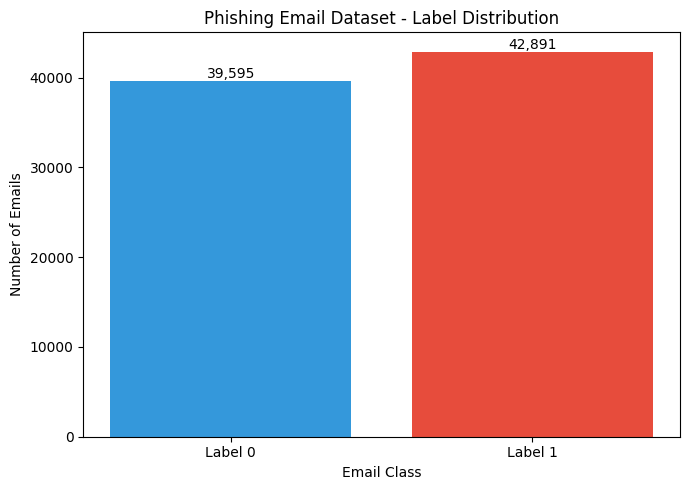

In [2]:
# STEP 1.2 - Label Distribution Visualization

import matplotlib.pyplot as plt

counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Label 0", "Label 1"],
    counts.values,
    color=["#3498db", "#e74c3c"]
)

plt.title("Phishing Email Dataset - Label Distribution")
plt.xlabel("Email Class")
plt.ylabel("Number of Emails")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Email Length Statistics:
count    8.248600e+04
mean     1.288751e+03
std      1.549675e+04
min      1.000000e+00
25%      2.760000e+02
50%      5.580000e+02
75%      1.338000e+03
max      4.279526e+06
Name: email_length, dtype: float64


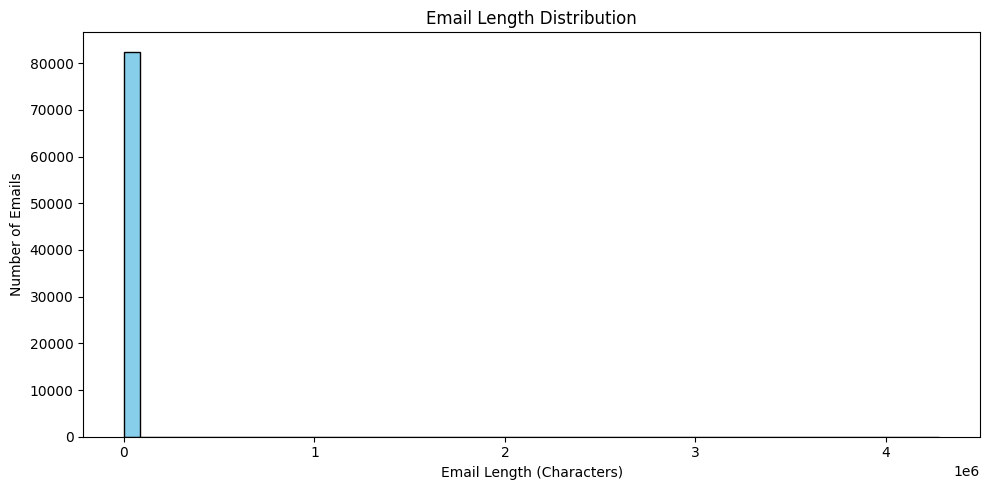

In [3]:
# STEP 1.3 - Email Length Analysis

# Calculate email length
df["email_length"] = df["text_combined"].astype(str).str.len()

# Display statistics
print("Email Length Statistics:")
print(df["email_length"].describe())

# Plot histogram
plt.figure(figsize=(10, 5))

plt.hist(
    df["email_length"],
    bins=50,
    color="skyblue",
    edgecolor="black"
)

plt.title("Email Length Distribution")
plt.xlabel("Email Length (Characters)")
plt.ylabel("Number of Emails")

plt.tight_layout()
plt.show()

99th Percentile: 9,014 characters


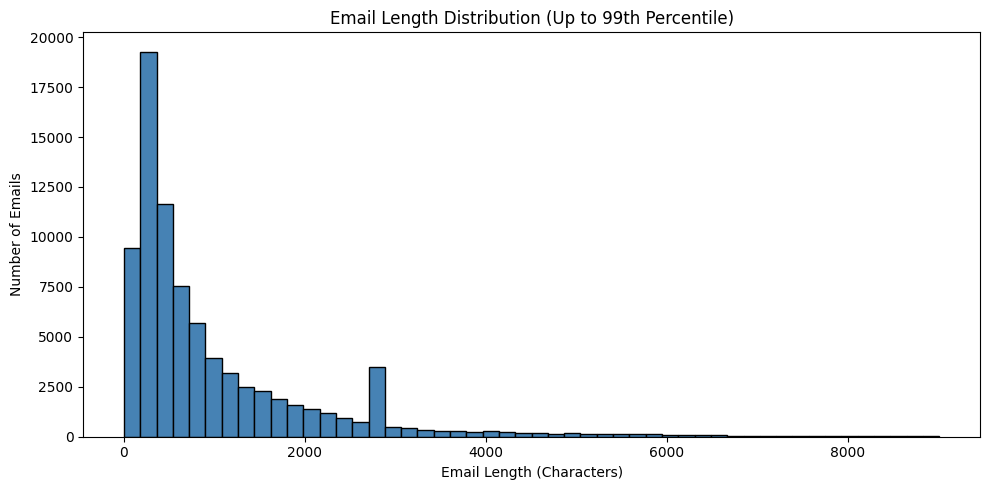

In [4]:
# STEP 1.3.1 - Improved Email Length Visualization

# Calculate the 99th percentile
p99 = df["email_length"].quantile(0.99)

print(f"99th Percentile: {p99:,.0f} characters")

# Plot emails within the 99th percentile
plt.figure(figsize=(10, 5))

plt.hist(
    df.loc[df["email_length"] <= p99, "email_length"],
    bins=50,
    color="steelblue",
    edgecolor="black"
)

plt.title("Email Length Distribution (Up to 99th Percentile)")
plt.xlabel("Email Length (Characters)")
plt.ylabel("Number of Emails")

plt.tight_layout()
plt.show()

In [5]:
# STEP 1.4 - Data Cleaning

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicated rows
df_clean = df_clean.drop_duplicates(
    subset=["text_combined", "label"]
).copy()

# Remove empty or whitespace-only emails
df_clean["text_combined"] = (
    df_clean["text_combined"]
    .astype(str)
    .str.strip()
)

df_clean = df_clean[
    df_clean["text_combined"].str.len() > 0
].copy()

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated(
    subset=["text_combined", "label"]
).sum())

Original dataset: (82486, 3)
Cleaned dataset: (82077, 3)
Remaining duplicates: 0


In [6]:
# STEP 1.5 - Data Quality Validation

# Check label distribution after cleaning
print("Label distribution after cleaning:")
print(df_clean["label"].value_counts())

# Check emails with conflicting labels
conflicting = (
    df_clean.groupby("text_combined")["label"]
    .nunique()
)

conflicting = conflicting[conflicting > 1]

print("\nEmails with conflicting labels:", len(conflicting))

# Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

# Check dataset size
print("\nFinal dataset shape:", df_clean.shape)

Label distribution after cleaning:
label
1    42844
0    39233
Name: count, dtype: int64

Emails with conflicting labels: 0

Missing values:
text_combined    0
label            0
email_length     0
dtype: int64

Final dataset shape: (82077, 3)


In [7]:
# STEP 2.1 - Train/Test Split

from sklearn.model_selection import train_test_split

# Input: email text
X = df_clean["text_combined"]

# Target: email label
y = df_clean["label"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 65661
Testing samples: 16416

Training label distribution:
label
1    34275
0    31386
Name: count, dtype: int64

Testing label distribution:
label
1    8569
0    7847
Name: count, dtype: int64


In [8]:
# STEP 2.2 - TF-IDF Feature Extraction

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype="float32"
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.get_feature_names_out()))

c:\Users\ADMIN\miniconda3\envs\aic211\lib\site-packages\sklearn\feature_extraction\text.py:2044: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Training TF-IDF shape: (65661, 10000)
Testing TF-IDF shape: (16416, 10000)
Vocabulary size: 10000


In [9]:
# STEP 3.1 - Multinomial Naive Bayes (Baseline)

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Initialize model
nb_model = MultinomialNB(alpha=1.0)

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Predict on test set
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate model
print("=== Multinomial Naive Bayes Results ===")
print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall   :", recall_score(y_test, y_pred_nb))
print("F1-score :", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

=== Multinomial Naive Bayes Results ===
Accuracy : 0.956140350877193
Precision: 0.9869710882243454
Recall   : 0.9282296650717703
F1-score : 0.9566995429396199

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      7847
           1       0.99      0.93      0.96      8569

    accuracy                           0.96     16416
   macro avg       0.96      0.96      0.96     16416
weighted avg       0.96      0.96      0.96     16416



In [10]:
# STEP 3.2 - Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Predict on test set
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluate model
print("=== Logistic Regression Results ===")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1-score :", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

=== Logistic Regression Results ===
Accuracy : 0.9853801169590644
Precision: 0.9821697348616417
Recall   : 0.989963823083207
F1-score : 0.9860513774264791

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      7847
           1       0.98      0.99      0.99      8569

    accuracy                           0.99     16416
   macro avg       0.99      0.99      0.99     16416
weighted avg       0.99      0.99      0.99     16416



In [11]:
# STEP 3.3 - Linear Support Vector Machine (SVM)

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Initialize SVM model
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Predict on test set
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate model
print("=== Linear SVM Results ===")

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall   :", recall_score(y_test, y_pred_svm))
print("F1-score :", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

=== Linear SVM Results ===
Accuracy : 0.9887914230019493
Precision: 0.9872167344567112
Recall   : 0.9913642198622943
F1-score : 0.9892861301968091

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7847
           1       0.99      0.99      0.99      8569

    accuracy                           0.99     16416
   macro avg       0.99      0.99      0.99     16416
weighted avg       0.99      0.99      0.99     16416



=== Model Performance Comparison ===


,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.9561,0.9870,0.9282,0.9567
1,Logistic Regression,0.9854,0.9822,0.9900,0.9861
2,Linear SVM,0.9888,0.9872,0.9914,0.9893


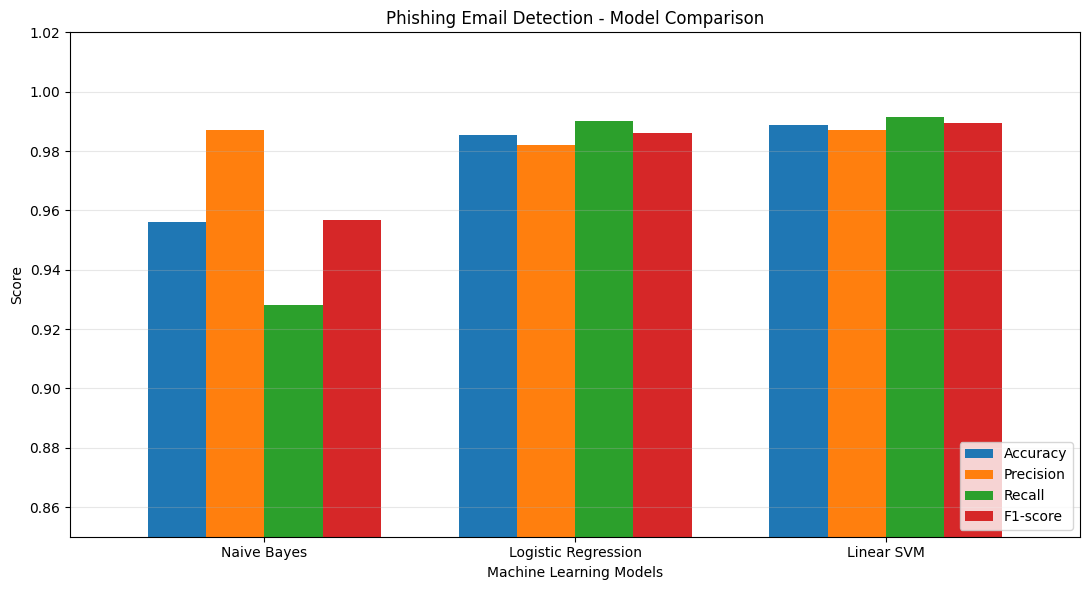

Chart saved: result/model_comparison.png


In [12]:
# STEP 3.4 - Model Performance Comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store predictions
predictions = {
    "Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "Linear SVM": y_pred_svm
}

# Calculate metrics
results = []

for model_name, y_pred in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

# Display comparison table
print("=== Model Performance Comparison ===")
display(results_df.round(4))

# Plot comparison chart
ax = results_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0.85, 1.02),
    width=0.75
)

plt.title("Phishing Email Detection - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../result/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved: result/model_comparison.png")

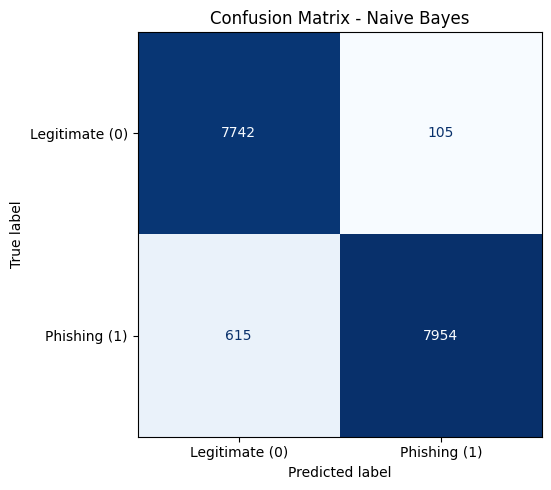


=== Naive Bayes ===
True Negative : 7742
False Positive: 105
False Negative: 615
True Positive : 7954


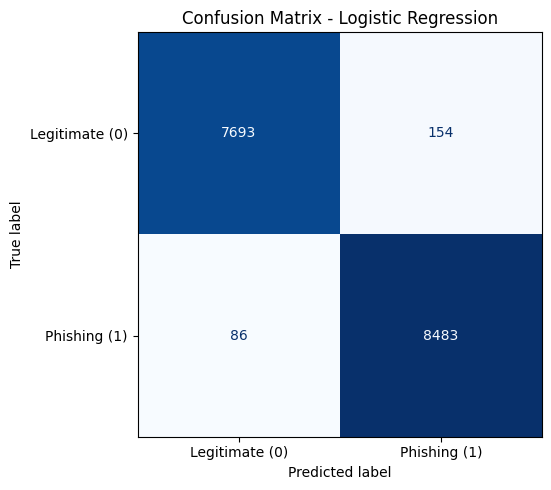


=== Logistic Regression ===
True Negative : 7693
False Positive: 154
False Negative: 86
True Positive : 8483


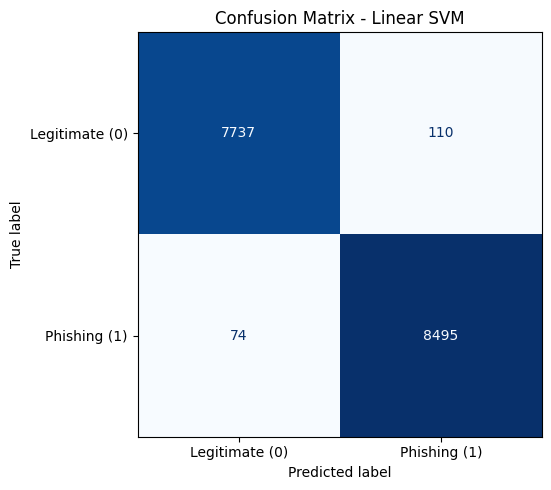


=== Linear SVM ===
True Negative : 7737
False Positive: 110
False Negative: 74
True Positive : 8495


In [13]:
# STEP 4.1 - Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_predictions = {
    "Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "Linear SVM": y_pred_svm
}

for model_name, y_pred in models_predictions.items():

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate (0)", "Phishing (1)"]
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")
    plt.savefig(
        f"../result/confusion_matrix_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\n=== {model_name} ===")
    print("True Negative :", cm[0, 0])
    print("False Positive:", cm[0, 1])
    print("False Negative:", cm[1, 0])
    print("True Positive :", cm[1, 1])

Naive Bayes - Average Precision: 0.9961
Logistic Regression - Average Precision: 0.9988
Linear SVM - Average Precision: 0.9992


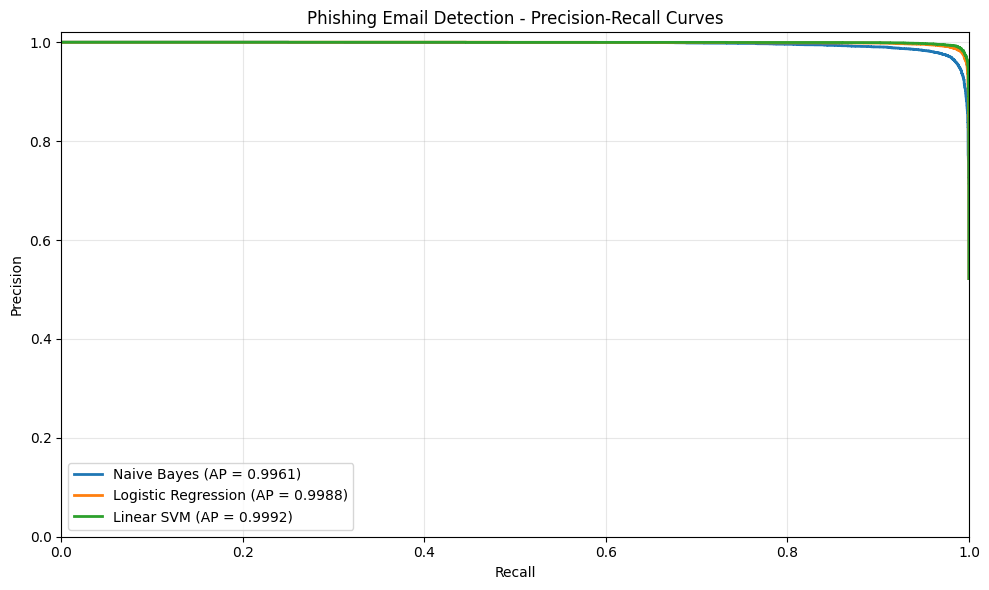

Chart saved: result/precision_recall_curve.png


In [14]:
# STEP 4.2 - Precision-Recall Curve and PR-AUC

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Calculate model scores
nb_scores = nb_model.predict_proba(X_test_tfidf)[:, 1]

lr_scores = lr_model.predict_proba(X_test_tfidf)[:, 1]

svm_scores = svm_model.decision_function(X_test_tfidf)

# Store scores
model_scores = {
    "Naive Bayes": nb_scores,
    "Logistic Regression": lr_scores,
    "Linear SVM": svm_scores
}

plt.figure(figsize=(10, 6))

for model_name, scores in model_scores.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, scores
    )

    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {ap:.4f})"
    )

    print(f"{model_name} - Average Precision: {ap:.4f}")

plt.title("Phishing Email Detection - Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../result/precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved: result/precision_recall_curve.png")

In [15]:
# STEP 4.3 - Data Leakage Validation

import pandas as pd

# Normalize email text for duplicate checking
def normalize_email(text):
    return " ".join(str(text).lower().split())

train_texts = pd.Series(X_train).map(normalize_email)
test_texts = pd.Series(X_test).map(normalize_email)

# Check duplicates within each dataset
train_duplicates = train_texts.duplicated().sum()
test_duplicates = test_texts.duplicated().sum()

# Check overlapping emails between train and test
overlapping = set(train_texts) & set(test_texts)

print("=== Data Leakage Validation ===")
print("Training samples:", len(train_texts))
print("Testing samples :", len(test_texts))

print("\nDuplicates in training set:", train_duplicates)
print("Duplicates in testing set :", test_duplicates)

print("\nOverlapping unique emails between train and test:",
      len(overlapping))

print("Test samples overlapping with training:",
      test_texts.isin(set(train_texts)).sum())

if len(overlapping) == 0:
    print("\nPASS: No exact normalized text overlap detected.")
else:
    print("\nWARNING: Potential data leakage detected!")

=== Data Leakage Validation ===
Training samples: 65661
Testing samples : 16416

Duplicates in training set: 0
Duplicates in testing set : 0

Overlapping unique emails between train and test: 0
Test samples overlapping with training: 0

PASS: No exact normalized text overlap detected.


In [16]:
# STEP 4.4 - Error Analysis (Linear SVM)

import pandas as pd
from sklearn.metrics import confusion_matrix

# Create a dataframe of test results
error_df = pd.DataFrame({
    "email_text": pd.Series(X_test).reset_index(drop=True),
    "actual_label": pd.Series(y_test).reset_index(drop=True),
    "predicted_label": y_pred_svm
})

# Identify incorrect predictions
errors = error_df[
    error_df["actual_label"] != error_df["predicted_label"]
].copy()

# False Positive: Legitimate email predicted as Phishing
false_positive = errors[
    (errors["actual_label"] == 0) &
    (errors["predicted_label"] == 1)
]

# False Negative: Phishing email predicted as Legitimate
false_negative = errors[
    (errors["actual_label"] == 1) &
    (errors["predicted_label"] == 0)
]

print("=== Linear SVM Error Analysis ===")

print("Total test samples:", len(error_df))
print("Total incorrect predictions:", len(errors))
print("False Positives:", len(false_positive))
print("False Negatives:", len(false_negative))

print("\n=== False Positive Examples ===")
display(false_positive.head(5))

print("\n=== False Negative Examples ===")
display(false_negative.head(5))

=== Linear SVM Error Analysis ===
Total test samples: 16416
Total incorrect predictions: 184
False Positives: 110
False Negatives: 74

=== False Positive Examples ===


,email_text,actual_label,predicted_label
40,joseph brennan vupzesmcolumbiaedu worked well ...,0,1
46,astrologycom feng shui fengshuirpastrologycom ...,0,1
56,expense please notify outstanding items expens...,0,1
75,diveintomark rssfeedsspamassassintaintorg url ...,0,1
136,iso2022jpbgyrcmetfbcehp04bkei hitoopentextcom ...,0,1



=== False Negative Examples ===


,email_text,actual_label,predicted_label
14,iceoe aoauau oauei ie caue aoe ei,1,0
581,human resources industrial relation occupation...,1,0
1102,sci fi convention hi asked pass might interest...,1,0
1150,davida davidamiramaxcom hi steph found talent ...,1,0
1940,pace modify schedule set realistic goals 81172...,1,0


=== Top 15 Phishing Indicators ===
2004: 3.3475
2017: 3.1209
2016: 2.9136
josemonkeyorg: 2.9051
2005: 2.7714
2018: 2.5781
remove: 2.4292
2019: 2.3869
2022: 2.0688
0300: 1.9238
http: 1.9222
may 2002: 1.9029
2020: 1.8635
life: 1.8571
meds: 1.7506

=== Top 15 Legitimate Indicators ===
enron: -5.5753
wrote: -4.7433
uai: -3.7255
vince: -3.7120
ierant: -3.5767
thanks: -3.3757
opensuse: -3.2117
louise: -3.2078
university: -3.0564
fork: -3.0294
tony: -2.8249
713: -2.6339
1300: -2.5989
daren: -2.4803
small business: -2.3248


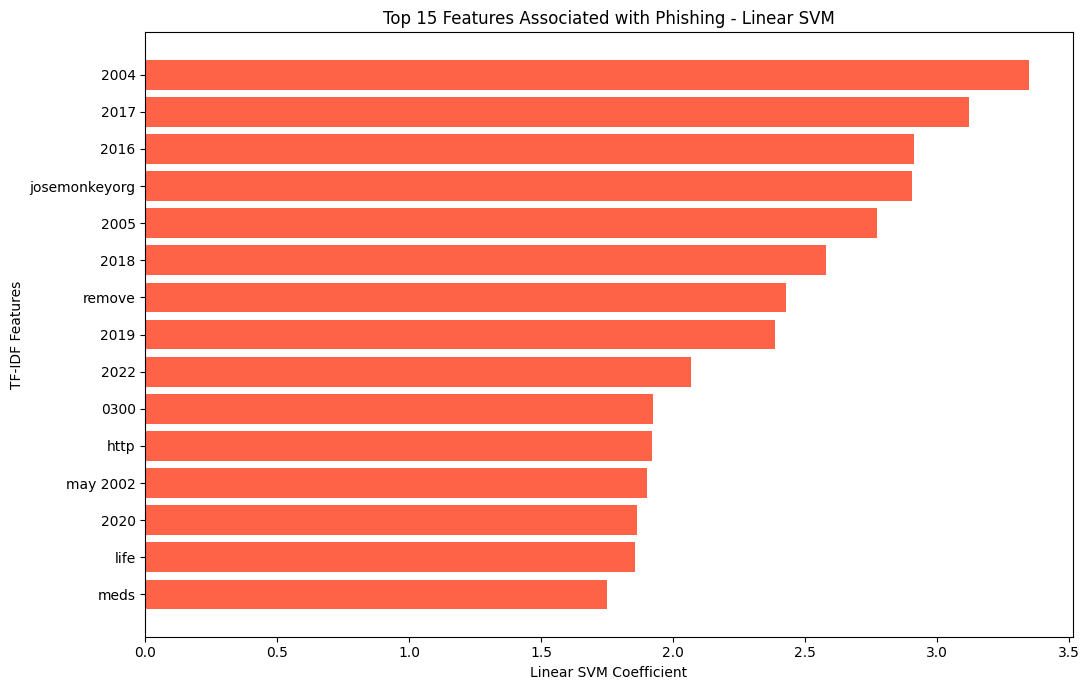

Chart saved: ../result/phishing_feature_importance.png


In [17]:
# STEP 5.1 - Explainable AI: Feature Importance

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Get feature names from TF-IDF
feature_names = np.array(tfidf.get_feature_names_out())

# Get Linear SVM coefficients
coefficients = svm_model.coef_[0]

# Select top 15 features for each class
top_phishing_idx = np.argsort(coefficients)[-15:][::-1]
top_legitimate_idx = np.argsort(coefficients)[:15]

print("=== Top 15 Phishing Indicators ===")
for idx in top_phishing_idx:
    print(f"{feature_names[idx]}: {coefficients[idx]:.4f}")

print("\n=== Top 15 Legitimate Indicators ===")
for idx in top_legitimate_idx:
    print(f"{feature_names[idx]}: {coefficients[idx]:.4f}")

# Visualize phishing indicators
top_features = feature_names[top_phishing_idx]
top_scores = coefficients[top_phishing_idx]

plt.figure(figsize=(11, 7))
plt.barh(top_features[::-1], top_scores[::-1], color="tomato")

plt.title("Top 15 Features Associated with Phishing - Linear SVM")
plt.xlabel("Linear SVM Coefficient")
plt.ylabel("TF-IDF Features")

plt.tight_layout()

# Save PNG
Path("../result").mkdir(parents=True, exist_ok=True)
plt.savefig("../result/phishing_feature_importance.png", dpi=300)

plt.show()

print("Chart saved: ../result/phishing_feature_importance.png")

In [18]:
# STEP 5.2 - Explainable Risk Scoring

import numpy as np
from scipy.special import expit

def analyze_email(email_text, top_n=5):

    # Transform email into TF-IDF features
    email_vector = tfidf.transform([email_text])

    # Get SVM decision score
    decision_score = svm_model.decision_function(email_vector)[0]

    # Convert to a 0-100 relative risk score
    # This is NOT a calibrated probability
    risk_score = float(expit(decision_score) * 100)

    prediction = svm_model.predict(email_vector)[0]

    # Calculate feature contributions
    contributions = (
        email_vector.multiply(svm_model.coef_)
        .toarray()
        .ravel()
    )

    feature_names = tfidf.get_feature_names_out()

    # Only consider features present in the email
    present_indices = email_vector.nonzero()[1]

    ranked_indices = sorted(
        present_indices,
        key=lambda i: contributions[i],
        reverse=True
    )

    phishing_features = [
        (feature_names[i], round(float(contributions[i]), 4))
        for i in ranked_indices
        if contributions[i] > 0
    ][:top_n]

    legitimate_features = [
        (feature_names[i], round(float(contributions[i]), 4))
        for i in ranked_indices[::-1]
        if contributions[i] < 0
    ][:top_n]

    print("=== Email Risk Analysis ===")
    print("Prediction:", "Phishing" if prediction == 1 else "Legitimate")
    print(f"Risk Score: {risk_score:.2f}/100")
    print("SVM Decision Score:", round(float(decision_score), 4))

    print("\nFeatures supporting Phishing:")
    for word, score in phishing_features:
        print(f"  {word}: +{score}")

    print("\nFeatures supporting Legitimate:")
    for word, score in legitimate_features:
        print(f"  {word}: {score}")

    return {
        "prediction": int(prediction),
        "risk_score": risk_score,
        "phishing_features": phishing_features,
        "legitimate_features": legitimate_features
    }


# Test with an example email
sample_email = """
Dear customer,
Your account has been suspended.
Please verify your account immediately by clicking the link.
Failure to respond may result in account termination.
"""

result = analyze_email(sample_email)

=== Email Risk Analysis ===
Prediction: Phishing
Risk Score: 80.49/100
SVM Decision Score: 1.4175

Features supporting Phishing:
  account: +0.3329
  dear customer: +0.3116
  immediately: +0.2741
  verify: +0.2392
  suspended: +0.1636

Features supporting Legitimate:
  please: -0.1254
  termination: -0.1028
  clicking: -0.0823
  respond: -0.0821
  may: -0.044


In [19]:
# STEP 6.1 - Save Trained Model and TF-IDF

import joblib
from pathlib import Path

# Project models directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save best model
joblib.dump(svm_model, model_dir / "linear_svm_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, model_dir / "tfidf_vectorizer.pkl")

print("=== Model Export Completed ===")
print("Saved: models/linear_svm_model.pkl")
print("Saved: models/tfidf_vectorizer.pkl")

# Verify saved files
loaded_model = joblib.load(model_dir / "linear_svm_model.pkl")
loaded_tfidf = joblib.load(model_dir / "tfidf_vectorizer.pkl")

test_email = "Please verify your account immediately."

test_vector = loaded_tfidf.transform([test_email])
prediction = loaded_model.predict(test_vector)[0]

print("\nModel loading test:")
print("Prediction:", "Phishing" if prediction == 1 else "Legitimate")

=== Model Export Completed ===
Saved: models/linear_svm_model.pkl
Saved: models/tfidf_vectorizer.pkl

Model loading test:
Prediction: Phishing
